### Welcome to the exercise about observational studies! This exercise will be hands on, and you will be able to practise the skills you developed so far!

## Propensity score matching

In this exercise, you will apply [propensity score matching](http://www.stewartschultz.com/statistics/books/Design%20of%20observational%20studies.pdf), which we discussed in lecture 6 ("Observational studies"), in order to draw conclusions from an observational study.

We will work with a by-now classic dataset from Robert LaLonde's study "[Evaluating the Econometric Evaluations of Training Programs](http://people.hbs.edu/nashraf/LaLonde_1986.pdf)" (1986).
The study investigated the effect of a job training program ("National Supported Work Demonstration") on the real earnings of an individual, a couple of years after completion of the program.
Your task is to determine the effectiveness of the "treatment" represented by the job training program.

#### Dataset description

- `treat`: 1 if the subject participated in the job training program, 0 otherwise
- `age`: the subject's age
- `educ`: years of education
- `race`: categorical variable with three possible values: Black, Hispanic, or White
- `married`: 1 if the subject was married at the time of the training program, 0 otherwise
- `nodegree`: 1 if the subject has earned no school degree, 0 otherwise
- `re74`: real earnings in 1974 (pre-treatment)
- `re75`: real earnings in 1975 (pre-treatment)
- `re78`: real earnings in 1978 (outcome)

If you want to deepen your knowledge on propensity scores and observational studies, we highly recommend Rosenbaum's excellent book on the ["Design of Observational Studies"](http://www.stewartschultz.com/statistics/books/Design%20of%20observational%20studies.pdf). Even just reading the first chapter (18 pages) will help you a lot.

In [1]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
%matplotlib inline
from statsmodels.stats import diagnostic
from scipy import stats

data_folder = './data/'
df = pd.read_csv(data_folder + 'lalonde.csv')

In [2]:
df.sample(10)

,id,treat,age,educ,black,hispan,married,nodegree,re74,re75,re78
217,PSID33,0,27,12,0,0,1,0,12270.8900,7709.129,7806.8290
387,PSID203,0,36,18,0,0,1,0,3273.9350,1269.339,18227.7600
358,PSID174,0,25,12,0,0,1,0,2721.4220,1754.516,1037.3640
357,PSID173,0,18,9,1,0,0,1,1183.3970,1822.548,803.8833
513,PSID329,0,21,15,0,0,0,0,2629.3360,0.000,1717.1180
78,NSW79,1,40,11,1,0,0,1,0.0000,0.000,23005.6000
9,NSW10,1,33,12,0,0,1,0,0.0000,0.000,12418.0700
561,PSID377,0,16,9,0,0,0,1,0.0000,0.000,4974.0280
141,NSW142,1,25,12,1,0,0,0,14426.7900,2409.274,0.0000
537,PSID353,0,19,11,0,0,0,1,540.7576,0.000,3406.1600


## 1. A naive analysis

Compare the distribution of the outcome variable (`re78`) between the two groups, using plots and numbers.
To summarize and compare the distributions, you may use the techniques we discussed in lecture 4 ("Descibing data") and 3 ("Visualizing data").

What might a naive "researcher" conclude from this superficial analysis?

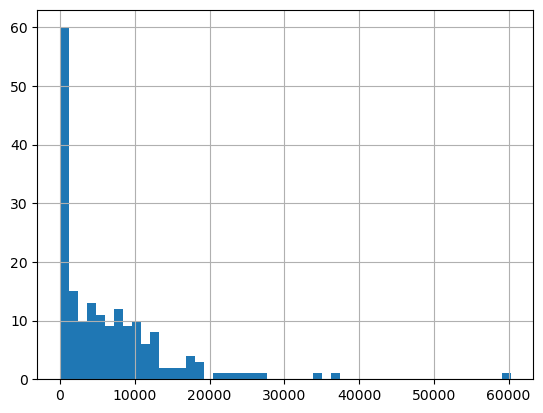

np.float64(6349.143530270271)

In [3]:
''' your code and explanations ''';
plt.close()
df.loc[df['treat'] == 1]['re78'].hist(bins = 50)
plt.show()
df.loc[df['treat'] == 1]['re78'].mean()

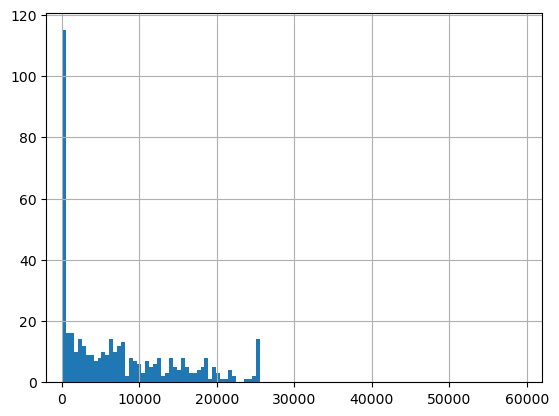

np.float64(6984.169742307692)

In [4]:
plt.close()
df.loc[df['treat'] == 0]['re78'].hist(bins = 50)
plt.xlim(-2000,62000)
plt.show()
df.loc[df['treat'] == 0]['re78'].mean()


In [6]:
'''The mean of people that did not participate is higher than the people that did. One could conclude that not doing the training would be better. 
But this could simply be because of the sample data, it doesn't look at how much it has increased from before.'''

"The mean of people that did not participate is higher than the people that did. One could conclude that not doing the training would be better. \nBut this could simply be because of the sample data, it doesn't look at how much it has increased from before."

## 2. A closer look at the data

You're not naive, of course (and even if you are, you've learned certain things in ADA), so you aren't content with a superficial analysis such as the above.
You're aware of the dangers of observational studies, so you take a closer look at the data before jumping to conclusions.

For each feature in the dataset, compare its distribution in the treated group with its distribution in the control group, using plots and numbers.
As above, you may use the techniques we discussed in class for summarizing and comparing the distributions.

What do you observe?
Describe what your observations mean for the conclusions drawn by the naive "researcher" from his superficial analysis.

In [7]:
''' your code and explanations ''';
stats.ttest_ind(df.loc[df['treat'] == 1]['re78'], df.loc[df['treat'] == 0]['re78'])

TtestResult(statistic=np.float64(-0.966352225446378), pvalue=np.float64(0.3342496685909654), df=np.float64(612.0))

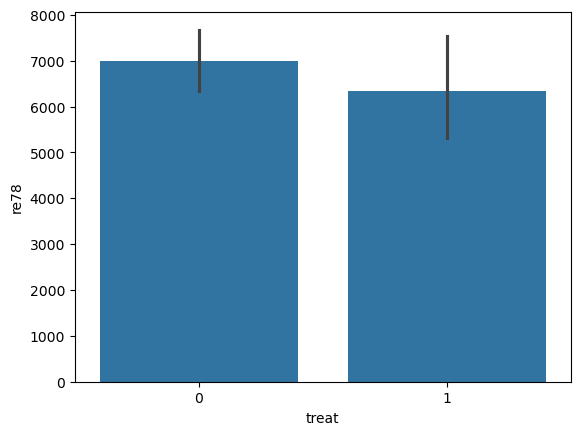

In [8]:
plt.close()
ax = sns.barplot(x="treat", y="re78", data=df.loc[df['treat'].isin([1,0])])
plt.show()

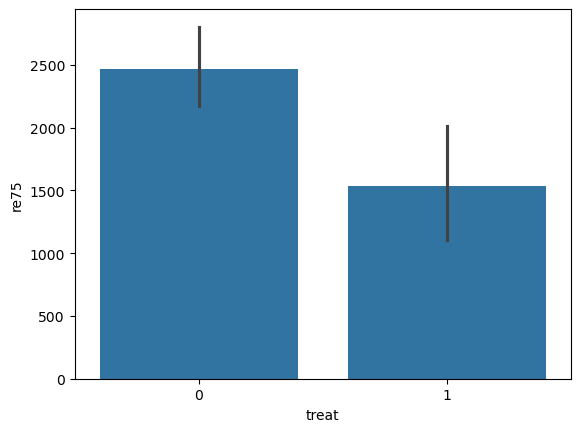

In [9]:
plt.close()
ax = sns.barplot(x="treat", y="re75", data=df.loc[df['treat'].isin([1,0])])
plt.show()

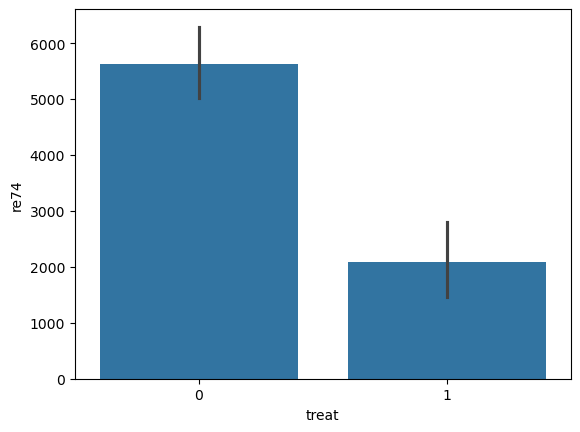

In [10]:
plt.close()
ax = sns.barplot(x="treat", y="re74", data=df.loc[df['treat'].isin([1,0])])
plt.show()

In [11]:
stats.pearsonr(df['treat'],df['re78'])

PearsonRResult(statistic=np.float64(-0.03903270530153821), pvalue=np.float64(0.33424966859096417))

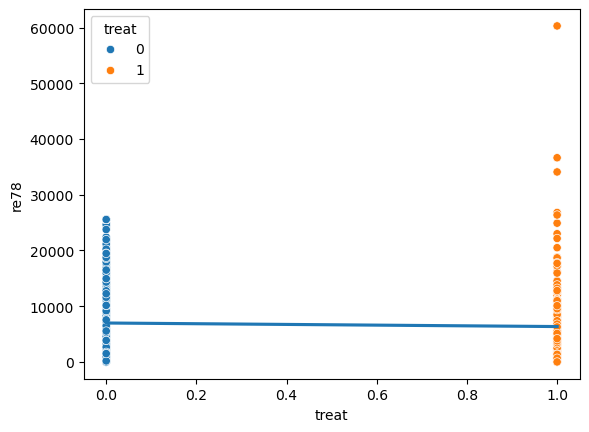

In [12]:
plt.close()
sns.scatterplot(x='treat', y='re78', hue='treat', data=df)
sns.regplot(x='treat', y='re78', data=df,
                scatter=False, ci=None)
plt.show()

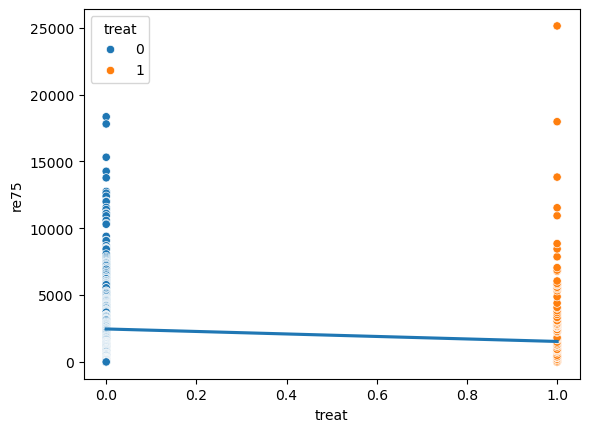

In [13]:
plt.close()
sns.scatterplot(x='treat', y='re75', hue='treat', data=df)
sns.regplot(x='treat', y='re75', data=df,
                scatter=False, ci=None)
plt.show()

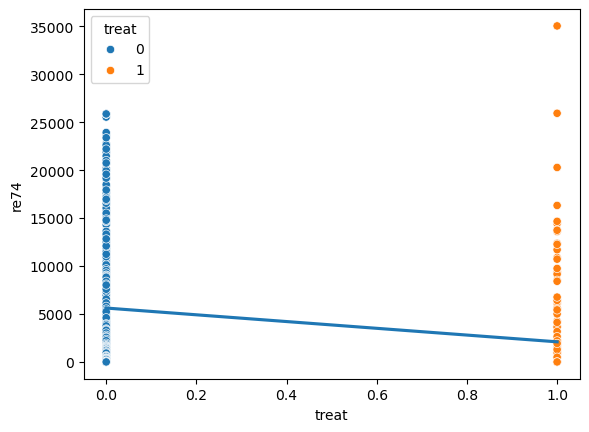

In [14]:
plt.close()
sns.scatterplot(x='treat', y='re74', hue='treat', data=df)
sns.regplot(x='treat', y='re74', data=df,
                scatter=False, ci=None)
plt.show()

In [15]:
df['sal_raise'] = df['re78']-df['re75']
df.sample()

,id,treat,age,educ,black,hispan,married,nodegree,re74,re75,re78,sal_raise
340,PSID156,0,20,13,0,0,0,0,0.0,2352.484,0.0,-2352.484


treat
0    4517.685299
1    4817.088216
Name: sal_raise, dtype: float64


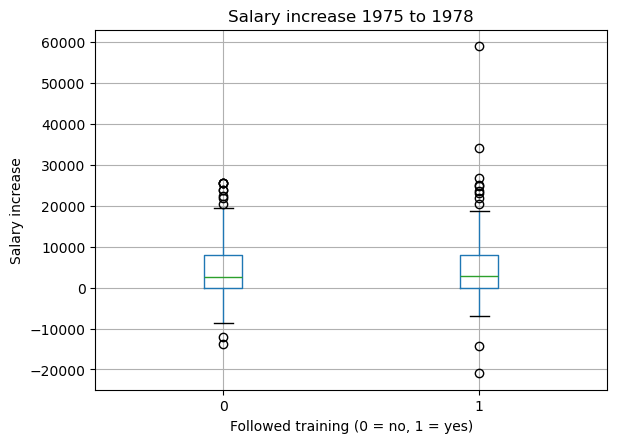

In [16]:
print(df.groupby("treat")["sal_raise"].mean())

# Boxplot comparing the two groups
df.boxplot(column="sal_raise", by="treat")
plt.title("Salary increase 1975 to 1978")
plt.suptitle("")
plt.xlabel("Followed training (0 = no, 1 = yes)")
plt.ylabel("Salary increase")
plt.show()

treat                  0             1
age  count    429.000000    185.000000
     mean      28.030303     25.816216
     std       10.786653      7.155019
     min       16.000000     17.000000
     25%       19.000000     20.000000
     50%       25.000000     25.000000
     75%       35.000000     29.000000
     max       55.000000     48.000000
educ count    429.000000    185.000000
     mean      10.235431     10.345946
     std        2.855238      2.010650
     min        0.000000      4.000000
     25%        9.000000      9.000000
     50%       11.000000     11.000000
     75%       12.000000     12.000000
     max       18.000000     16.000000
re74 count    429.000000    185.000000
     mean    5619.236506   2095.573689
     std     6788.750796   4886.620353
     min        0.000000      0.000000
     25%        0.000000      0.000000
     50%     2547.047000      0.000000
     75%     9277.128000   1291.468000
     max    25862.320000  35040.070000
re75 count    429.000000 

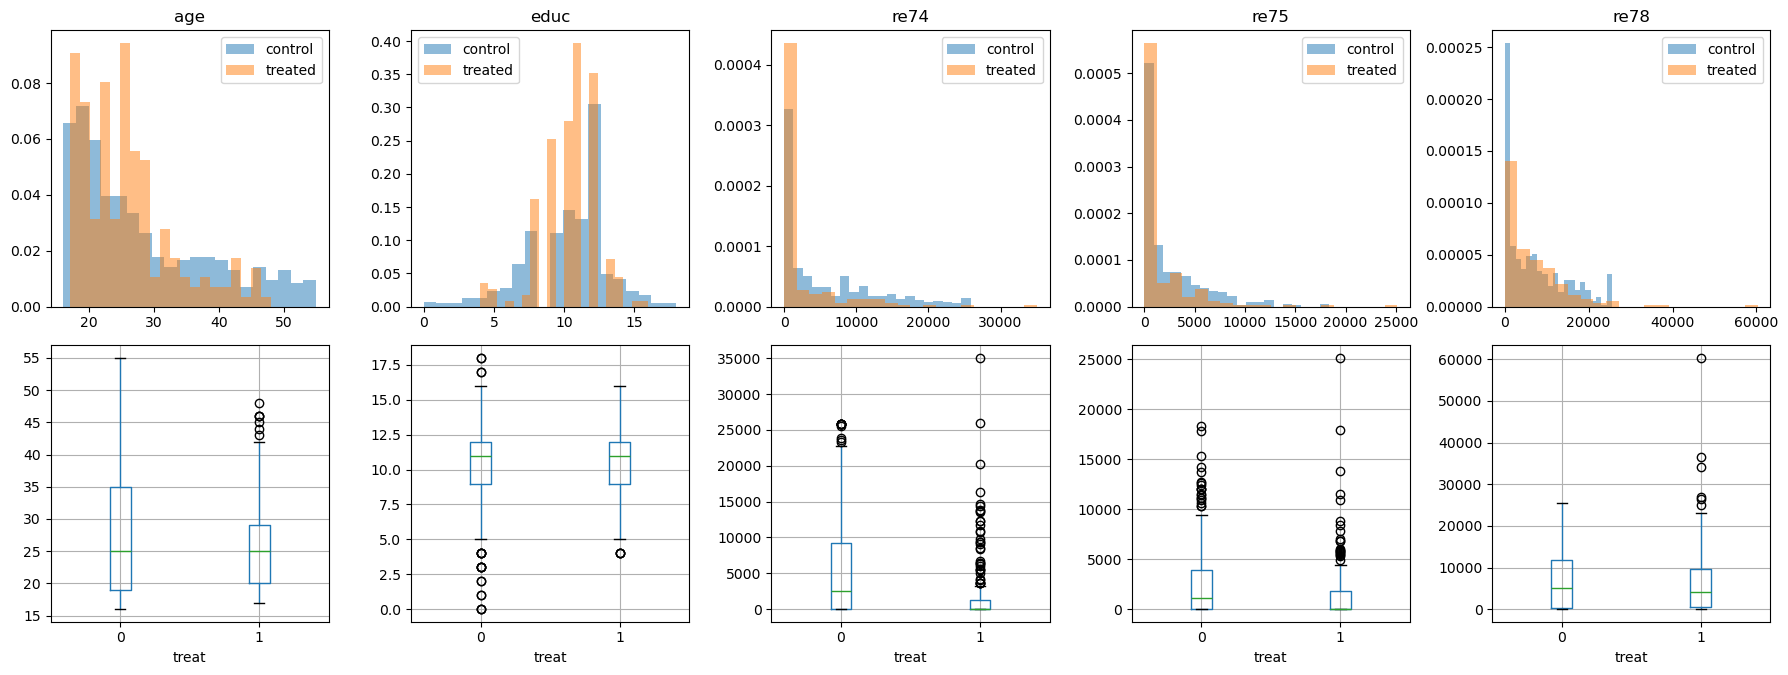

        married  nodegree     black    hispan     white
treat                                                  
0      0.512821  0.596737  0.202797  0.142191  0.655012
1      0.189189  0.708108  0.843243  0.059459  0.097297


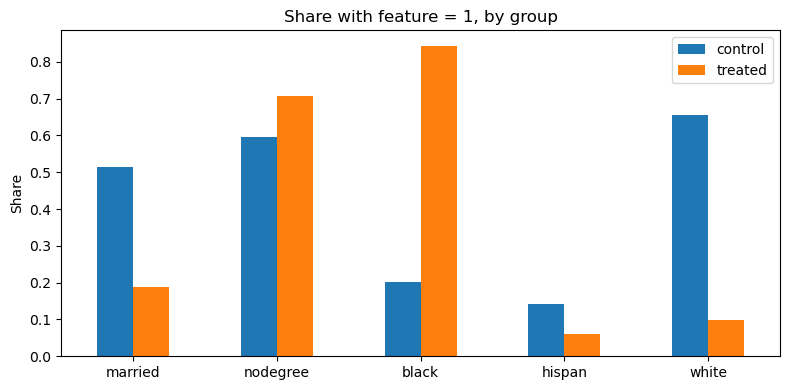

In [18]:
treated = df[df["treat"] == 1]
control = df[df["treat"] == 0]

# ---------- Numeric features: age, educ, re74, re75, re78 ----------
num_cols = ["age", "educ", "re74", "re75", "re78"]

# Numbers: summary stats per group
print(df.groupby("treat")[num_cols].describe().T)

# Standardized mean difference (rule of thumb: |SMD| > 0.1 = imbalance)
def smd(col):
    pooled_sd = np.sqrt((treated[col].var() + control[col].var()) / 2)
    return (treated[col].mean() - control[col].mean()) / pooled_sd

print(pd.Series({c: smd(c) for c in num_cols}, name="SMD"))

# Share of people with zero earnings (important for earnings variables)
for c in ["re74", "re75", "re78"]:
    print(c, "share zero:", df.groupby("treat")[c].apply(lambda s: (s == 0).mean()).round(2).to_dict())

# Plots: overlaid histograms + boxplots
fig, axes = plt.subplots(2, len(num_cols), figsize=(18, 7))
for i, c in enumerate(num_cols):
    axes[0, i].hist(control[c], bins=20, alpha=0.5, density=True, label="control")
    axes[0, i].hist(treated[c], bins=20, alpha=0.5, density=True, label="treated")
    axes[0, i].set_title(c)
    axes[0, i].legend()
    df.boxplot(column=c, by="treat", ax=axes[1, i])
    axes[1, i].set_title("")
plt.suptitle("")
plt.tight_layout()
plt.show()

# ---------- Binary features: married, nodegree, black, hispan ----------
bin_cols = ["married", "nodegree", "black", "hispan"]

# White = neither black nor hispan
df["white"] = ((df["black"] == 0) & (df["hispan"] == 0)).astype(int)
bin_cols_all = bin_cols + ["white"]

# Numbers: share with value 1 in each group
print(df.groupby("treat")[bin_cols_all].mean())

# Plot: grouped bar chart of the shares
shares = df.groupby("treat")[bin_cols_all].mean().T
shares.columns = ["control", "treated"]
shares.plot(kind="bar", figsize=(8, 4))
plt.title("Share with feature = 1, by group")
plt.ylabel("Share")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. A propensity score model

Use logistic regression to estimate propensity scores for all points in the dataset.
You may use `statsmodels` to fit the logistic regression model and apply it to each data point to obtain propensity scores.

Recall that the propensity score of a data point represents its probability of receiving the treatment, based on its pre-treatment features (in this case, age, education, pre-treatment income, etc.).
To brush up on propensity scores, you may read chapter 3.3 of the above-cited book by Rosenbaum or [this article](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC3144483/pdf/hmbr46-399.pdf).

Note: you do not need a train/test split here. Train and apply the model on the entire dataset. If you're wondering why this is the right thing to do in this situation, recall that the propensity score model is not used in order to make predictions about unseen data. Its sole purpose is to balance the dataset across treatment groups.
(See p. 74 of Rosenbaum's book for an explanation why slight overfitting is even good for propensity scores.
If you want even more information, read [this article](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC3144483/pdf/hmbr46-399.pdf).)

Optimization terminated successfully.
         Current function value: 0.397267
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                  treat   No. Observations:                  614
Model:                          Logit   Df Residuals:                      605
Method:                           MLE   Df Model:                            8
Date:                Tue, 13 Oct 2026   Pseudo R-squ.:                  0.3508
Time:                        11:21:08   Log-Likelihood:                -243.92
converged:                       True   LL-Null:                       -375.75
Covariance Type:            nonrobust   LLR p-value:                 2.194e-52
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -4.7286      1.017     -4.649      0.000      -6.722      -2.735
age            0.0158      0.

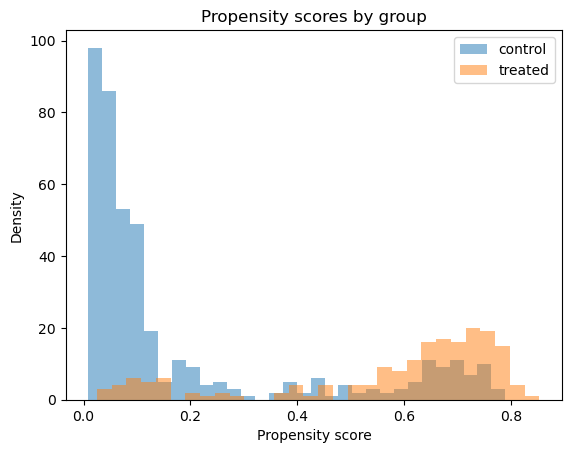

In [21]:
''' your code and explanations ''';
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Pre-treatment features only (no re78, since that is the outcome)
features = ["age", "educ", "married", "nodegree", "black", "hispan", "re74", "re75"]

X = sm.add_constant(df[features])
y = df["treat"]

# Fit logistic regression on the whole dataset (no train/test split)
logit_model = sm.Logit(y, X).fit()
print(logit_model.summary())

# Propensity score = predicted probability of treatment for every row
df["pscore"] = logit_model.predict(X)

# Quick look at the scores per group
print(df.groupby("treat")["pscore"].describe())

# Plot: overlap of propensity scores between the groups
plt.hist(df.loc[df["treat"] == 0, "pscore"], bins=30, alpha=0.5, density=False, label="control")
plt.hist(df.loc[df["treat"] == 1, "pscore"], bins=30, alpha=0.5, density=False, label="treated")
plt.xlabel("Propensity score")
plt.ylabel("Density")
plt.title("Propensity scores by group")
plt.legend()
plt.show()

In [22]:
'''propensity scores are different. to get a good randomized comparison we should compare only the subgroup with porpensity scores above 0.4. 
everything below is not distributed evenly.'''

'propensity scores are different. to get a good randomized comparison we should compare only the subgroup with porpensity scores above 0.4. \neverything below is not distributed evenly.'

## 4. Balancing the dataset via matching

Use the propensity scores to match each data point from the treated group with exactly one data point from the control group, while ensuring that each data point from the control group is matched with at most one data point from the treated group.
(Hint: you may explore the `networkx` package in Python for predefined matching functions.)

Your matching should maximize the similarity between matched subjects, as captured by their propensity scores.
In other words, the sum (over all matched pairs) of absolute propensity-score differences between the two matched subjects should be minimized.

This is how networkx library can help you do this. Each possible pair of (treated_person, control_person) is characterized by a similarity. This is how we can initialize a graph, and add an edge for one possible pair. We then need to add an edge for each possible pair.
    - G = nx.Graph()
    - G.add_weighted_edges_from([(control_person, treated_person, similarity)])
Optimal matching is then found with:
    - matching = nx.max_weight_matching(G)

After matching, you have as many treated as you have control subjects.
Compare the outcomes (`re78`) between the two groups (treated and control).

Also, compare again the feature-value distributions between the two groups, as you've done in part 2 above, but now only for the matched subjects.
What do you observe?
Are you closer to being able to draw valid conclusions now than you were before?

Matched pairs: 185
Mean re78, treated: 6349.143530270271
Mean re78, control: 5454.7760499999995
Difference: 894.3674802702717
Naive difference (full data): -635.0262120374209


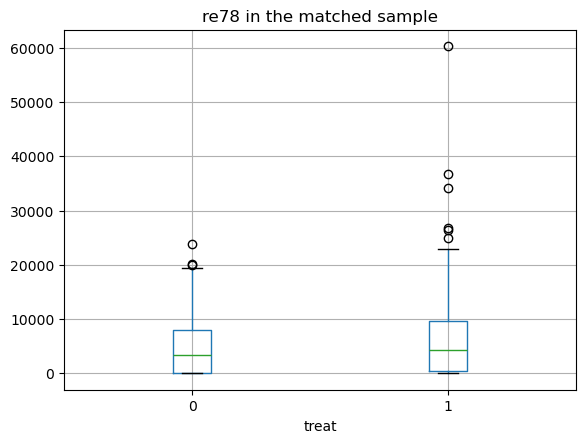

          treated_mean_before  control_mean_before  SMD_before  \
age                    25.816               28.030      -0.242   
educ                   10.346               10.235       0.045   
re74                 2095.574             5619.237      -0.596   
re75                 1532.055             2466.484      -0.287   
married                 0.189                0.513      -0.719   
nodegree                0.708                0.597       0.235   
black                   0.843                0.203       1.668   
hispan                  0.059                0.142      -0.277   

          treated_mean_after  control_mean_after  SMD_after  
age                   25.816              25.303      0.057  
educ                  10.346              10.605     -0.110  
re74                2095.574            2342.108     -0.054  
re75                1532.055            1614.745     -0.028  
married                0.189               0.211     -0.054  
nodegree               0.708     

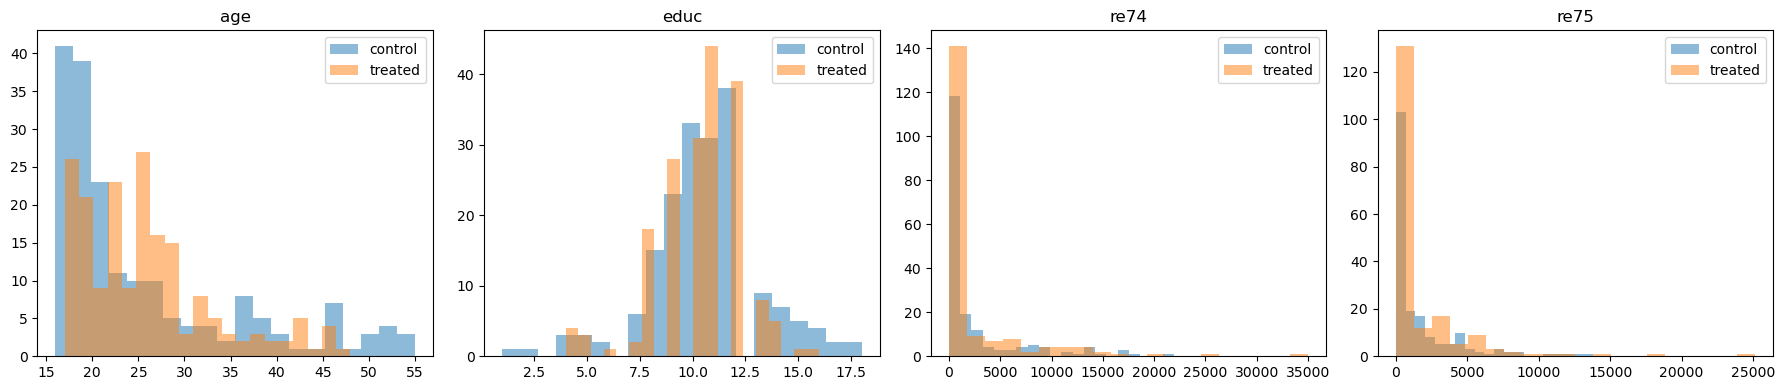

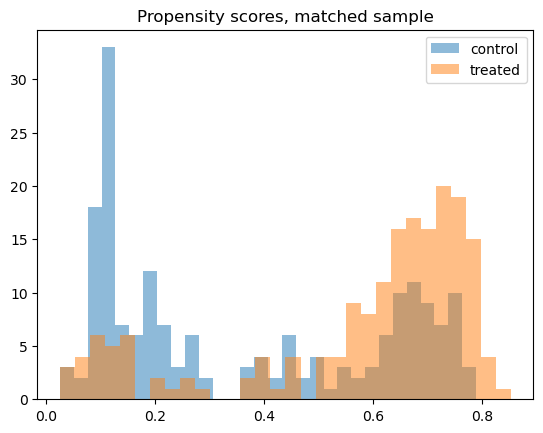

In [25]:
''' your code and explanations ''';
treated = df[df["treat"] == 1]
control = df[df["treat"] == 0]
# ---------- Build the bipartite graph ----------
# Weight = similarity. Using 1 - |difference| means maximizing total weight
# is the same as minimizing total absolute pscore difference (the constant
# is the same for every pair, and a full matching has a fixed number of pairs).
G = nx.Graph()
for t_idx, t_score in treated["pscore"].items():
    for c_idx, c_score in control["pscore"].items():
        similarity = 1 - abs(t_score - c_score)
        G.add_edge(("T", t_idx), ("C", c_idx), weight=similarity)

# maxcardinality=True forces every treated person to get a match
# (without it, networkx may leave some pairs unmatched to maximize weight)
matching = nx.max_weight_matching(G, maxcardinality=True)

# ---------- Collect matched pairs ----------
pairs = []
for a, b in matching:
    t_node, c_node = (a, b) if a[0] == "T" else (b, a)
    pairs.append((t_node[1], c_node[1]))

treated_idx = [t for t, c in pairs]
control_idx = [c for t, c in pairs]
matched = pd.concat([df.loc[treated_idx], df.loc[control_idx]])
matched_t = matched[matched["treat"] == 1]
matched_c = matched[matched["treat"] == 0]
print("Matched pairs:", len(pairs))

# ---------- Compare outcomes ----------
print("Mean re78, treated:", matched_t["re78"].mean())
print("Mean re78, control:", matched_c["re78"].mean())
print("Difference:", matched_t["re78"].mean() - matched_c["re78"].mean())
print("Naive difference (full data):",
      df.loc[df.treat == 1, "re78"].mean() - df.loc[df.treat == 0, "re78"].mean())

matched.boxplot(column="re78", by="treat")
plt.suptitle("")
plt.title("re78 in the matched sample")
plt.show()

# ---------- Balance check on matched sample ----------
all_cols = ["age", "educ", "re74", "re75", "married", "nodegree", "black", "hispan"]

def smd_between(a, b, col):
    pooled_sd = np.sqrt((a[col].var() + b[col].var()) / 2)
    return (a[col].mean() - b[col].mean()) / pooled_sd

balance = pd.DataFrame({
    "treated_mean_before": treated[all_cols].mean(),
    "control_mean_before": control[all_cols].mean(),
    "SMD_before": pd.Series({c: smd_between(treated, control, c) for c in all_cols}),
    "treated_mean_after": matched_t[all_cols].mean(),
    "control_mean_after": matched_c[all_cols].mean(),
    "SMD_after": pd.Series({c: smd_between(matched_t, matched_c, c) for c in all_cols}),
})
print(balance.round(3))

# ---------- Plots: matched sample ----------
num_cols = ["age", "educ", "re74", "re75"]
fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    ax.hist(matched_c[c], bins=20, alpha=0.5, density=False, label="control")
    ax.hist(matched_t[c], bins=20, alpha=0.5, density=False, label="treated")
    ax.set_title(c)
    ax.legend()
plt.tight_layout()
plt.show()

# Propensity score overlap after matching
plt.hist(matched_c["pscore"], bins=30, alpha=0.5, label="control")
plt.hist(matched_t["pscore"], bins=30, alpha=0.5, label="treated")
plt.title("Propensity scores, matched sample")
plt.legend()
plt.show()

In [26]:
'''The naive difference was -$635, which suggests the training hurts earnings. After matching, the difference is +$894, which suggests it helps.
The sign flips because treated people started out much poorer (re74 of 2,096 vs 5,619 for controls). The naive comparison confounds the training with those pre-existing differences.
This is the pattern you’d expect from selection bias: the naive analysis understated the effect.
Still badly imbalanced: black has an SMD of 0.852 after matching (down from 1.668, but far from balanced): 84% of treated people are Black vs 47% of matched controls. hispan (-0.466) is also unbalanced, with 6% treated vs 22% matched controls.'''

'Still badly imbalanced: black has an SMD of 0.852 after matching (down from 1.668, but far from balanced): 84% of treated people are Black vs 47% of matched controls. hispan (-0.466) is also unbalanced, with 6% treated vs 22% matched controls.'

## 5. Balancing the groups further

Based on your comparison of feature-value distributions from part 4, are you fully satisfied with your matching?
Would you say your dataset is sufficiently balanced?
If not, in what ways could the "balanced" dataset you have obtained still not allow you to draw valid conclusions?

Improve your matching by explicitly making sure that you match only subjects that have the same value for the problematic feature.
Argue with numbers and plots that the two groups (treated and control) are now better balanced than after part 4.


In [27]:
''' Am I fully satisfied with the part 4 matching? No.

Most features are balanced, but black (SMD 0.85) and hispan (SMD -0.47) are not. 84% of treated subjects are Black vs 47% of matched controls, so the two groups are not comparable on race. educ (-0.11) and nodegree (0.15) are also slightly above the 0.1 rule of thumb.

This could still prevent valid conclusions for three reasons:

Confounding by race. If race is related to earnings growth between 1975 and 1978 (through labor market conditions or discrimination, for example), the +$894 mixes the training effect with a race effect.
Balance on the propensity score is not balance on every feature. The score is a summary. Two people can share a score through different feature combinations, and matching only guarantees balance if the score model is right.
Unobserved confounders. Matching can only balance what we measured. Motivation, for example, could still differ between the groups.''';


treat       0    1
race_grp          
black      87  156
hispan     61   11
white     281   18
Matched pairs: 116
Mean re78, treated: 6166.431752586207
Mean re78, control: 5095.456025431035
Difference: 1070.9757271551716
          SMD_part4  SMD_exact  treated_mean  control_mean_part4  \
age           0.057     -0.050        25.681              25.303   
educ         -0.110     -0.104        10.121              10.605   
re74         -0.054     -0.057      2782.527            2342.108   
re75         -0.028     -0.061      1743.704            1614.745   
married      -0.054     -0.078         0.241               0.211   
nodegree      0.150      0.108         0.672               0.638   
black         0.852      0.000         0.750               0.470   
hispan       -0.466      0.000         0.095               0.216   

          control_mean_exact  
age                   26.138  
educ                  10.379  
re74                3090.710  
re75                1952.239  
married    

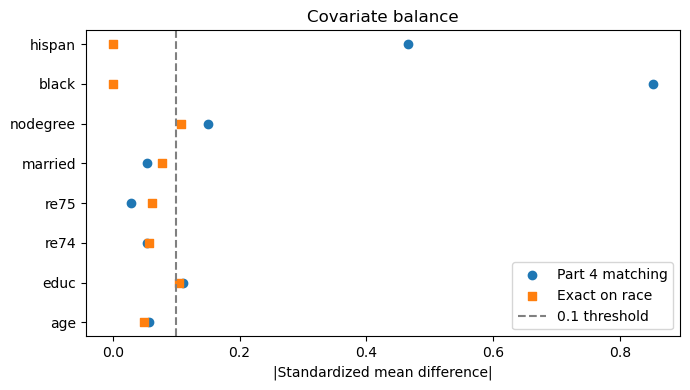

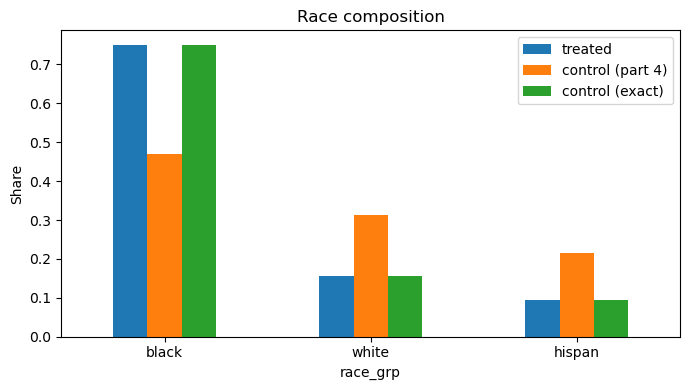

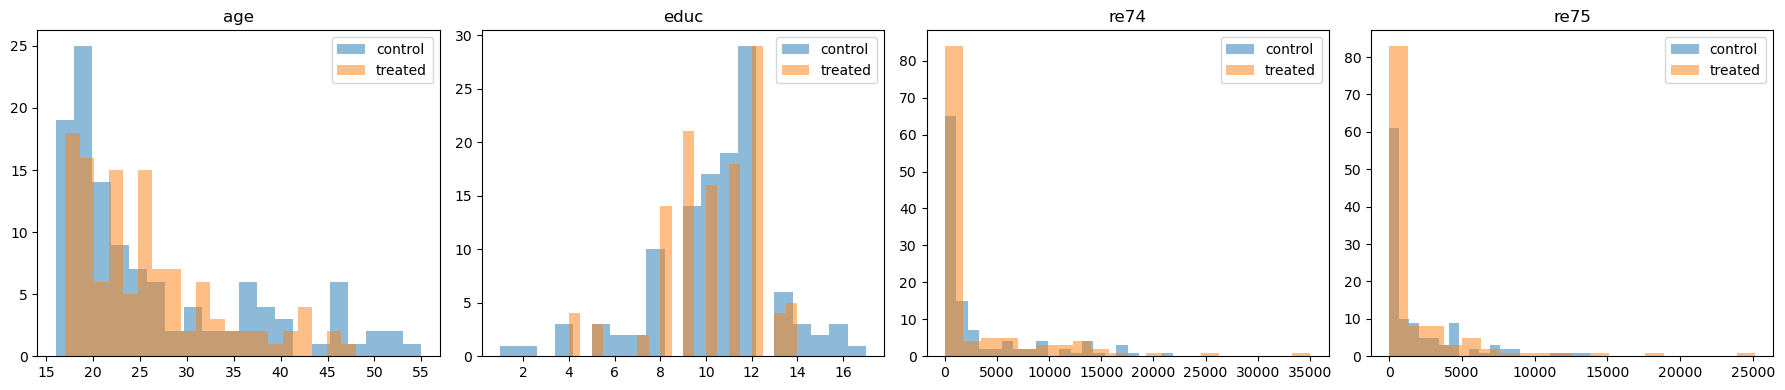

In [29]:
# Race group label: black / hispan / white (white = neither)
df["race_grp"] = np.where(df["black"] == 1, "black",
                  np.where(df["hispan"] == 1, "hispan", "white"))

# Check there are enough controls in each group
print(pd.crosstab(df["race_grp"], df["treat"]))

# Keep the part 4 matched samples for comparison
matched4_t, matched4_c = matched_t.copy(), matched_c.copy()

# ---------- Match separately within each race group ----------
pairs_exact = []
for grp in df["race_grp"].unique():
    t_g = df[(df["treat"] == 1) & (df["race_grp"] == grp)]
    c_g = df[(df["treat"] == 0) & (df["race_grp"] == grp)]

    G = nx.Graph()
    for t_idx, t_score in t_g["pscore"].items():
        for c_idx, c_score in c_g["pscore"].items():
            G.add_edge(("T", t_idx), ("C", c_idx), weight=1 - abs(t_score - c_score))

    m = nx.max_weight_matching(G, maxcardinality=True)
    for a, b in m:
        t_node, c_node = (a, b) if a[0] == "T" else (b, a)
        pairs_exact.append((t_node[1], c_node[1]))

matched_t2 = df.loc[[t for t, c in pairs_exact]]
matched_c2 = df.loc[[c for t, c in pairs_exact]]
print("Matched pairs:", len(pairs_exact))

# Sanity check: every pair has the same race group
assert all(df.loc[t, "race_grp"] == df.loc[c, "race_grp"] for t, c in pairs_exact)

# ---------- Outcomes ----------
print("Mean re78, treated:", matched_t2["re78"].mean())
print("Mean re78, control:", matched_c2["re78"].mean())
print("Difference:", matched_t2["re78"].mean() - matched_c2["re78"].mean())

# ---------- Balance: part 4 vs exact-on-race ----------
cols = ["age", "educ", "re74", "re75", "married", "nodegree", "black", "hispan"]

def smd_between(a, b, col):
    sd = np.sqrt((a[col].var() + b[col].var()) / 2)
    return (a[col].mean() - b[col].mean()) / sd if sd > 0 else 0.0

balance = pd.DataFrame({
    "SMD_part4": pd.Series({c: smd_between(matched4_t, matched4_c, c) for c in cols}),
    "SMD_exact": pd.Series({c: smd_between(matched_t2, matched_c2, c) for c in cols}),
    "treated_mean": matched_t2[cols].mean(),
    "control_mean_part4": matched4_c[cols].mean(),
    "control_mean_exact": matched_c2[cols].mean(),
})
print(balance.round(3))
print("Max |SMD| part 4:", round(balance["SMD_part4"].abs().max(), 3))
print("Max |SMD| exact: ", round(balance["SMD_exact"].abs().max(), 3))

# ---------- Plot 1: SMD comparison ("love plot") ----------
y = np.arange(len(cols))
plt.figure(figsize=(7, 4))
plt.scatter(balance["SMD_part4"].abs(), y, label="Part 4 matching", marker="o")
plt.scatter(balance["SMD_exact"].abs(), y, label="Exact on race", marker="s")
plt.axvline(0.1, color="gray", linestyle="--", label="0.1 threshold")
plt.yticks(y, cols)
plt.xlabel("|Standardized mean difference|")
plt.title("Covariate balance")
plt.legend()
plt.tight_layout()
plt.show()

# ---------- Plot 2: race composition, treated vs controls ----------
comp = pd.DataFrame({
    "treated": matched_t2["race_grp"].value_counts(normalize=True),
    "control (part 4)": matched4_c.assign(race_grp=df.loc[matched4_c.index, "race_grp"])["race_grp"].value_counts(normalize=True),
    "control (exact)": matched_c2["race_grp"].value_counts(normalize=True),
}).fillna(0)
comp.plot(kind="bar", figsize=(7, 4))
plt.title("Race composition")
plt.ylabel("Share")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ---------- Plot 3: numeric feature distributions, matched sample ----------
num_cols = ["age", "educ", "re74", "re75"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    ax.hist(matched_c2[c], bins=20, alpha=0.5, density=False, label="control")
    ax.hist(matched_t2[c], bins=20, alpha=0.5, density=False, label="treated")
    ax.set_title(c)
    ax.legend()
plt.tight_layout()
plt.show()

In [32]:
'''What you can conclude
The point estimate suggests the program raised earnings by roughly $1,000 for participants. Whether that is distinguishable from zero depends on the paired t-test and bootstrap CI from the snippet, which I haven’t seen. With only 116 pairs and very variable earnings, the CI could well include zero. If it excludes zero, you can say the evidence supports a positive effect. If it includes zero, say the estimate is positive but inconclusive, which is not the same as “no effect”.

Limitations to mention

Dropped treated subjects. The estimate now applies to the 116 matched treated subjects, not all 185. Black treated subjects are underrepresented (75% of the matched sample vs 84% originally), and the algorithm kept those with the closest control matches. So the result may not generalize to the dropped group.
Small sample. The white (18) and Hispanic (11) groups are matched on very few treated subjects, so the estimate is noisy.
Unobserved confounders. Only measured features are balanced. Something like motivation could still bias the estimate.
Residual imbalance. A regression of re78 on treat plus the covariates in the matched sample is a useful robustness check.'''

'What you can conclude\nThe point estimate suggests the program raised earnings by roughly $1,000 for participants. Whether that is distinguishable from zero depends on the paired t-test and bootstrap CI from the snippet, which I haven’t seen. With only 116 pairs and very variable earnings, the CI could well include zero. If it excludes zero, you can say the evidence supports a positive effect. If it includes zero, say the estimate is positive but inconclusive, which is not the same as “no effect”.\n\nLimitations to mention\n\nDropped treated subjects. The estimate now applies to the 116 matched treated subjects, not all 185. Black treated subjects are underrepresented (75% of the matched sample vs 84% originally), and the algorithm kept those with the closest control matches. So the result may not generalize to the dropped group.\nSmall sample. The white (18) and Hispanic (11) groups are matched on very few treated subjects, so the estimate is noisy.\nUnobserved confounders. Only meas

## 6. A less naive analysis

Compare the outcomes (`re78`) between treated and control subjects, as you've done in part 1, but now only for the matched dataset you've obtained from part 5.
What do you conclude about the effectiveness of the job training program?

Mean re78, treated: 6166.4
Mean re78, control: 5095.5
Difference (matched): 1071.0
Median re78, treated / control: 4300.659 2256.4885000000004
Share with zero re78, treated / control: 0.22 0.28
Naive difference (full data): -635.0
Paired t-test: t = 1.27, p = 0.205
95% bootstrap CI: [-562.8 2765.9]


C:\Users\mario\AppData\Local\Temp\ipykernel_30076\553832830.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([c_re78, t_re78], labels=["control", "treated"])


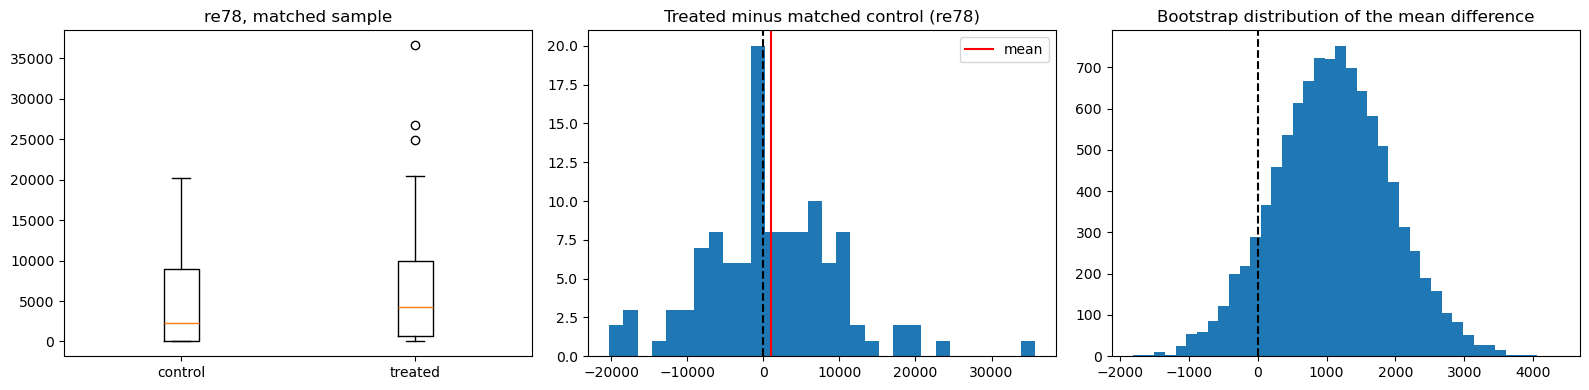

In [30]:
''' your code and explanations ''';
# ---------- Means and difference ----------
t_re78 = matched_t2["re78"].to_numpy()
c_re78 = matched_c2["re78"].to_numpy()

# Pair the outcomes (the order matches pairs_exact)
pair_diff = np.array([df.loc[t, "re78"] - df.loc[c, "re78"] for t, c in pairs_exact])

print("Mean re78, treated:", t_re78.mean().round(1))
print("Mean re78, control:", c_re78.mean().round(1))
print("Difference (matched):", pair_diff.mean().round(1))
print("Median re78, treated / control:", np.median(t_re78), np.median(c_re78))
print("Share with zero re78, treated / control:",
      (t_re78 == 0).mean().round(2), (c_re78 == 0).mean().round(2))

# For comparison: naive and part 4 estimates
print("Naive difference (full data):",
      (df.loc[df.treat == 1, "re78"].mean() - df.loc[df.treat == 0, "re78"].mean()).round(1))

# ---------- Is the difference distinguishable from zero? ----------
# Paired t-test on the pair differences
t_stat, p_val = stats.ttest_1samp(pair_diff, 0)
print(f"Paired t-test: t = {t_stat:.2f}, p = {p_val:.3f}")

# Bootstrap 95% confidence interval (resample pairs)
rng = np.random.default_rng(0)
boot = [rng.choice(pair_diff, size=len(pair_diff), replace=True).mean() for _ in range(10000)]
print("95% bootstrap CI:", np.percentile(boot, [2.5, 97.5]).round(1))

# ---------- Plots ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Boxplot of re78 by group
axes[0].boxplot([c_re78, t_re78], labels=["control", "treated"])
axes[0].set_title("re78, matched sample")

# 2. Histogram of the pair differences
axes[1].hist(pair_diff, bins=30)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].axvline(pair_diff.mean(), color="red", label="mean")
axes[1].set_title("Treated minus matched control (re78)")
axes[1].legend()

# 3. Bootstrap distribution of the mean difference
axes[2].hist(boot, bins=40)
axes[2].axvline(0, color="black", linestyle="--")
axes[2].set_title("Bootstrap distribution of the mean difference")

plt.tight_layout()
plt.show()

In [33]:
'''What the numbers say

Paired t-test: t = 1.27, p = 0.205. This is well above the usual 0.05 threshold.
95% bootstrap CI: [-563, 2766]. It includes zero. The data are consistent with anything from a small negative effect to a gain of nearly $2,800 per year.
Both methods agree, which makes the conclusion more robust.

Other signals (suggestive, not conclusive)

Medians: treated $4,301 vs control $2,256. The gap in medians (about $2,000) is larger than the gap in means, so the typical treated person seems to do better, while a few high earners in the control group pull its mean up.
Zero earnings: 22% of treated vs 28% of controls had no earnings in 1978. A lower share of non-earners could mean the program helps with finding employment. With 116 pairs, a 6-point gap could easily be chance, and you haven’t tested it.'''

'What the numbers say\n\nPaired t-test: t = 1.27, p = 0.205. This is well above the usual 0.05 threshold.\n95% bootstrap CI: [-563, 2766]. It includes zero. The data are consistent with anything from a small negative effect to a gain of nearly $2,800 per year.\nBoth methods agree, which makes the conclusion more robust.\n\nOther signals (suggestive, not conclusive)\n\nMedians: treated $4,301 vs control $2,256. The gap in medians (about $2,000) is larger than the gap in means, so the typical treated person seems to do better, while a few high earners in the control group pull its mean up.\nZero earnings: 22% of treated vs 28% of controls had no earnings in 1978. A lower share of non-earners could mean the program helps with finding employment. With 116 pairs, a 6-point gap could easily be chance, and you haven’t tested it.'

In [36]:
'''After matching treated and control subjects on propensity score and exactly on race, the groups were well balanced on all observed features (max |SMD| = 0.11). Treated subjects earned $1,071 more on average in 1978 than matched controls, a reversal of the naive estimate of -$635. However, this difference is not statistically significant (paired t-test p = 0.21; 95% bootstrap CI [-563, 2766]). We therefore cannot conclude that the program is effective, though the point estimate and the higher median earnings among treated subjects are consistent with a positive effect. Limitations include the small matched sample (116 pairs, with 69 treated subjects dropped), the possibility of unmeasured confounders, and a small residual imbalance in education.'''

'After matching treated and control subjects on propensity score and exactly on race, the groups were well balanced on all observed features (max |SMD| = 0.11). Treated subjects earned $1,071 more on average in 1978 than matched controls, a reversal of the naive estimate of -$635. However, this difference is not statistically significant (paired t-test p = 0.21; 95% bootstrap CI [-563, 2766]). We therefore cannot conclude that the program is effective, though the point estimate and the higher median earnings among treated subjects are consistent with a positive effect. Limitations include the small matched sample (116 pairs, with 69 treated subjects dropped), the possibility of unmeasured confounders, and a small residual imbalance in education.'